# K-MEANS CLUSTERING

In [3]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt

In [4]:
df = pd.read_csv("Customer_Data.csv")

In [5]:
# Show first rows
print(df.head(10))

# Shape and info
print(df.shape)
print(df.info())
print(df.isnull().sum())


   CustomerID  Age  Annual_Income  Spending_Score
0           1   56          23343              17
1           2   69          33500              13
2           3   46          73222              84
3           4   32          49375              25
4           5   60          29662              68
5           6   25          36964              10
6           7   38          79638              67
7           8   56          93666              18
8           9   36         105067             100
9          10   40          87215              86
(500, 4)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 4 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   CustomerID      500 non-null    int64
 1   Age             500 non-null    int64
 2   Annual_Income   500 non-null    int64
 3   Spending_Score  500 non-null    int64
dtypes: int64(4)
memory usage: 15.8 KB
None
CustomerID        0
Age            

In [6]:
# 2. Select Numeric Features
features = ["Annual_Income", "Spending_Score"]
X = df[features]

In [7]:
# 3. Data Cleaning + Standardization
X = X.fillna(X.mean())

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [8]:
# 4. Apply K-Means for Different K Values
k_values = [2, 3, 5]
sil_scores = {}

for k in k_values:
    km = KMeans(n_clusters=k, random_state=42)
    labels = km.fit_predict(X_scaled)

    df[f"K{k}_Label"] = labels

    sil = silhouette_score(X_scaled, labels)
    sil_scores[k] = sil
    print(f"Silhouette Score for K={k}: {sil}")

Silhouette Score for K=2: 0.35361539468854614
Silhouette Score for K=3: 0.3818010982451029
Silhouette Score for K=5: 0.3909297934969663


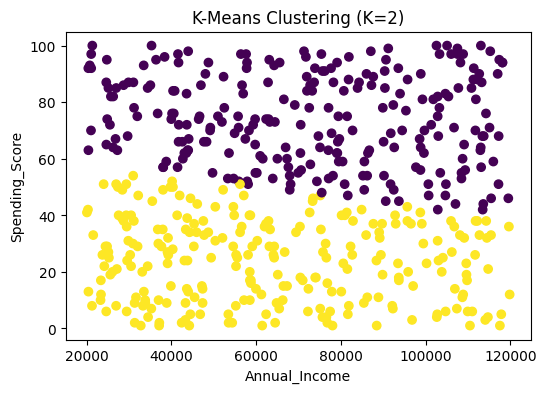

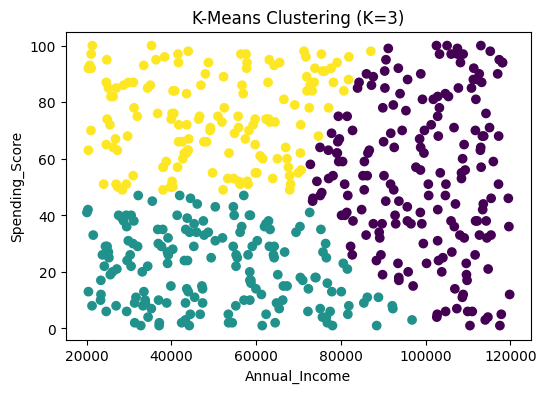

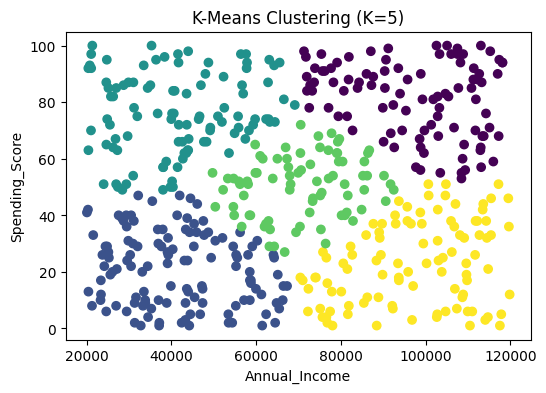

In [10]:
# 5. Visualization for each K
for k in k_values:
    plt.figure(figsize=(6,4))
    plt.scatter(df[features[0]], df[features[1]], c=df[f"K{k}_Label"])
    plt.xlabel(features[0])
    plt.ylabel(features[1])
    plt.title(f"K-Means Clustering (K={k})")
    plt.show()


In [11]:

# 6. Print all silhouette scores
print("Silhouette Scores:", sil_scores)

Silhouette Scores: {2: np.float64(0.35361539468854614), 3: np.float64(0.3818010982451029), 5: np.float64(0.3909297934969663)}


# HIERARCHICAL CLUSTERING

In [13]:
from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.cluster import AgglomerativeClustering

In [14]:
# Use the same features as K-Means
X = df[features]

In [15]:
# Standardize again
X_scaled = scaler.fit_transform(X)


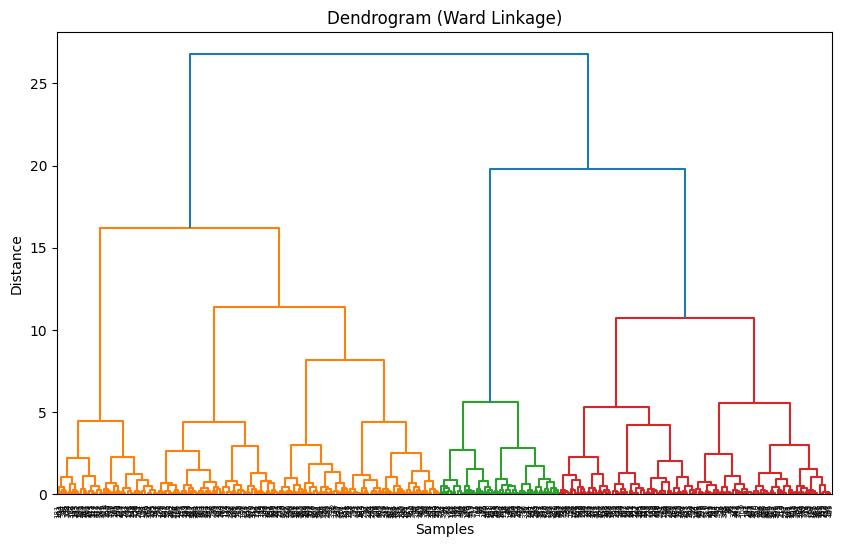

In [16]:
# 3. Create Dendrogram
plt.figure(figsize=(10, 6))
dendrogram(linkage(X_scaled, method="ward"))
plt.title("Dendrogram (Ward Linkage)")
plt.xlabel("Samples")
plt.ylabel("Distance")
plt.show()

In [17]:
n_clusters = 3   # Example

# 5. Agglomerative Clustering
hc = AgglomerativeClustering(
    n_clusters=n_clusters,
    metric="euclidean",
    linkage="ward"
)

df["HC_Label"] = hc.fit_predict(X_scaled)

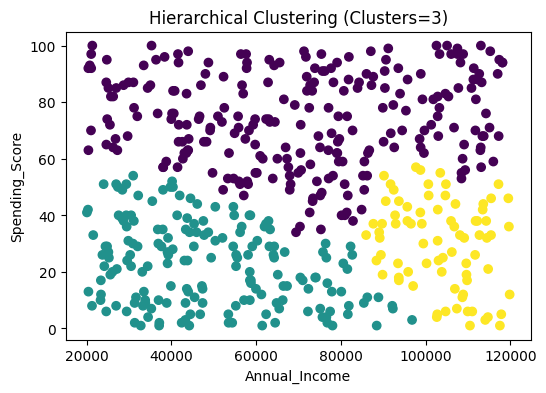

In [18]:
# 6. Visualization
plt.figure(figsize=(6,4))
plt.scatter(df[features[0]], df[features[1]], c=df["HC_Label"])
plt.xlabel(features[0])
plt.ylabel(features[1])
plt.title(f"Hierarchical Clustering (Clusters={n_clusters})")
plt.show()

# PCA

In [31]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

In [32]:
# --------------------------------------------------------
# 1. Load & Explore Data
# --------------------------------------------------------

df = pd.read_csv("FlowerData.csv")

print(df.head(10))
print("Shape:", df.shape)
print(df.describe())
print("Missing Values:\n", df.isnull().sum())

    Length1    Width1   Length2    Width2  Class
0  3.559971  2.594485  3.110798  1.441980  TypeC
1  6.728929  2.108289  5.251406  1.354200  TypeC
2  5.525967  1.428583  7.237675  0.356413  TypeC
3  4.792622  2.941385  6.393349  1.050745  TypeB
4  2.358103  2.554194  6.839367  1.136430  TypeB
5  2.357970  0.987851  5.952700  1.177410  TypeB
6  1.819460  3.232782  6.153659  1.576379  TypeC
7  6.263969  2.967612  7.095174  1.473926  TypeB
8  4.806133  3.349400  3.498008  1.637391  TypeA
9  5.394399  2.677159  4.936550  1.982743  TypeA
Shape: (500, 5)
          Length1      Width1     Length2      Width2
count  500.000000  500.000000  500.000000  500.000000
mean     4.242089    1.945854    5.105349    1.392248
std      1.642786    0.856480    1.783158    0.631422
min      1.527839    0.513896    2.029640    0.307080
25%      2.827038    1.187298    3.447368    0.830363
50%      4.322401    1.915465    5.238430    1.419561
75%      5.658687    2.679010    6.664063    1.922228
max      6.96

In [34]:
# --------------------------------------------------------
# 2. Prepare Data
# --------------------------------------------------------

# Select only numeric columns
features = ["Length1", "Width1", "Length2", "Width2"]   # change if dataset has different names
X = df[features]

# Standardize features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)


Explained Variance (PCA 2): [0.26424838 0.25292485]
Total Variance Retained (2 PCs): 0.5171732283424632


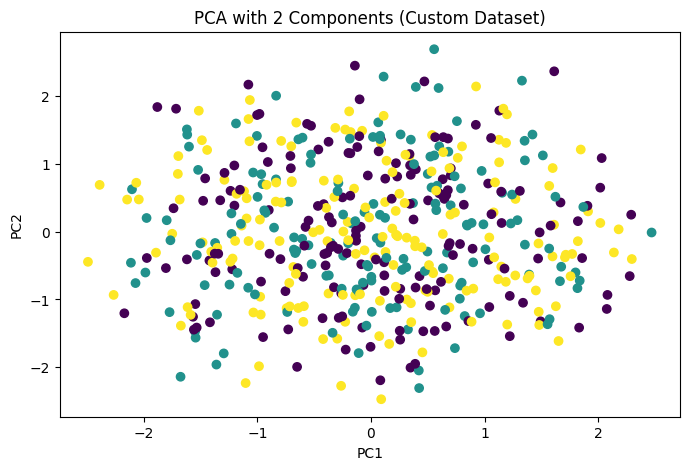

In [36]:
# --------------------------------------------------------
# 3a. PCA with 2 Components
# --------------------------------------------------------

pca_2 = PCA(n_components=2)
X_pca_2 = pca_2.fit_transform(X_scaled)

df["PC1"] = X_pca_2[:, 0]
df["PC2"] = X_pca_2[:, 1]

print("\nExplained Variance (PCA 2):", pca_2.explained_variance_ratio_)
print("Total Variance Retained (2 PCs):", pca_2.explained_variance_ratio_.sum())

# 2D scatter plot
plt.figure(figsize=(8,5))
plt.scatter(df["PC1"], df["PC2"],
            c=pd.factorize(df["Class"])[0] if "Class" in df.columns else "blue")

plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("PCA with 2 Components (Custom Dataset)")
plt.show()


Explained Variance (PCA 3): [0.26424838 0.25292485 0.24954627]
Total Variance Retained (3 PCs): 0.7667194961658569


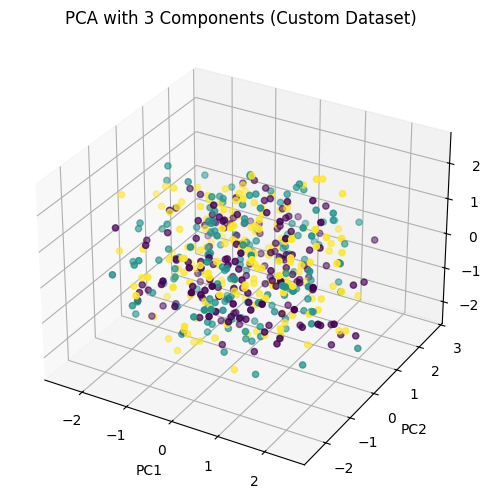

In [37]:

# --------------------------------------------------------
# 3b. PCA with 3 Components
# --------------------------------------------------------

pca_3 = PCA(n_components=3)
X_pca_3 = pca_3.fit_transform(X_scaled)

df["PC1_3"] = X_pca_3[:, 0]
df["PC2_3"] = X_pca_3[:, 1]
df["PC3_3"] = X_pca_3[:, 2]

print("\nExplained Variance (PCA 3):", pca_3.explained_variance_ratio_)
print("Total Variance Retained (3 PCs):", pca_3.explained_variance_ratio_.sum())

# 3D scatter plot
fig = plt.figure(figsize=(8,6))
ax = fig.add_subplot(111, projection="3d")

ax.scatter(df["PC1_3"], df["PC2_3"], df["PC3_3"],
           c=pd.factorize(df["Class"])[0] if "Class" in df.columns else "blue")

ax.set_xlabel("PC1")
ax.set_ylabel("PC2")
ax.set_zlabel("PC3")
ax.set_title("PCA with 3 Components (Custom Dataset)")

plt.show()